# JS13 [Artificial Neural Network (ANN) dan Evaluasi Classifier]
**Nama:** Sharren Elvaretta

**Kelas:** TI-3G

**NIM:** 244107020191

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import tensorflow as tf
from google.colab import files

# Upload file CSV dataset lettuce
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
df = pd.read_csv(nama_file)

print("Ukuran data:", df.shape)
df.head()

Saving lettuce_dataset_training_fix.csv to lettuce_dataset_training_fix.csv
Ukuran data: (2212, 9)


,22,8/3/2023,33.4,70,620,6.2,1,92.12,0.7
0,22,8/4/2023,33.5,63,800,6.5,2,92.30,0.63
1,22,8/5/2023,33.4,50,602,6.0,3,92.12,0.50
2,22,8/6/2023,33.4,50,721,6.0,4,92.12,0.50
3,22,8/7/2023,33.4,65,571,6.3,5,92.12,0.65
4,22,8/8/2023,32.3,77,631,6.8,6,90.14,0.77


In [3]:
df.info()
print()
print("Missing value per kolom:")
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2212 entries, 0 to 2211
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   22        2212 non-null   int64  
 1   8/3/2023  2212 non-null   object 
 2   33.4      2212 non-null   float64
 3   70        2212 non-null   int64  
 4   620       2212 non-null   int64  
 5   6.2       2212 non-null   float64
 6   1         2212 non-null   int64  
 7   92.12     2212 non-null   float64
 8   0.7       2212 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 155.7+ KB

Missing value per kolom:
22          0
8/3/2023    0
33.4        0
70          0
620         0
6.2         0
1           0
92.12       0
0.7         0
dtype: int64


,22,33.4,70,620,6.2,1,92.12,0.7
count,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000
mean,46.030289,27.064647,64.753165,598.860759,6.398463,23.094937,80.716365,0.647532
std,14.137321,5.004014,9.036466,116.863822,0.234569,13.037677,9.007224,0.090365
min,22.000000,18.000000,50.000000,400.000000,6.000000,1.000000,64.400000,0.500000
25%,34.000000,22.200000,57.000000,496.750000,6.200000,12.000000,71.960000,0.570000
50%,46.000000,29.800000,65.000000,593.000000,6.400000,23.000000,85.640000,0.650000
75%,58.000000,31.300000,73.000000,702.000000,6.600000,34.000000,88.340000,0.730000
max,70.000000,33.500000,80.000000,800.000000,6.800000,48.000000,92.300000,0.800000


In [4]:
print("Kolom:", list(df.columns))

TARGET = df.columns[-1]      # <- ganti jika target bukan kolom terakhir, contoh: TARGET = 'Growth Days'
print("Target:", TARGET)

df = df.dropna().reset_index(drop=True)

Kolom: ['22', '8/3/2023', '33.4', '70', '620', '6.2', '1', '92.12', '0.7']
Target: 0.7


### Preprocessing


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Fitur
X = pd.get_dummies(df.drop(columns=[TARGET])).astype(float)
n_fitur = X.shape[1]

# Target
y_raw = df[TARGET]
target_kontinu = pd.api.types.is_numeric_dtype(y_raw) and y_raw.nunique() > 10

if target_kontinu:
    y_reg = y_raw.values.astype(float)
    y_cls = pd.qcut(y_raw, q=3, labels=False, duplicates='drop').values   # 0,1,2
    nama_kelas = [f"Kelas {k}" for k in np.unique(y_cls)]
else:
    y_reg = None
    le = LabelEncoder()
    y_cls = le.fit_transform(y_raw)
    nama_kelas = [str(c) for c in le.classes_]

n_kelas = len(np.unique(y_cls))
print("Jumlah fitur :", n_fitur)
print("Target kontinu (bisa regresi):", target_kontinu)
print("Jumlah kelas :", n_kelas, "->", nama_kelas)
print(pd.Series(y_cls).value_counts().sort_index())

Jumlah fitur : 55
Target kontinu (bisa regresi): True
Jumlah kelas : 3 -> ['Kelas 0', 'Kelas 1', 'Kelas 2']
0    742
1    765
2    705
Name: count, dtype: int64


In [6]:
# Split data klasifikasi (80% latih, 20% uji) + normalisasi fitur
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test  = scaler_X.transform(X_test)

# One-hot encoding label (untuk Keras, sama seperti Praktikum 2)
y_train_oh = tf.keras.utils.to_categorical(y_train, n_kelas)
y_test_oh  = tf.keras.utils.to_categorical(y_test, n_kelas)

print("Data latih:", X_train.shape, " Data uji:", X_test.shape)

Data latih: (1769, 55)  Data uji: (443, 55)


### 1.1 Confusion Matrix, Accuracy, Precision, Recall

Confusion Matrix:
[[100  49   0]
 [ 43  85  25]
 [  4  57  80]]


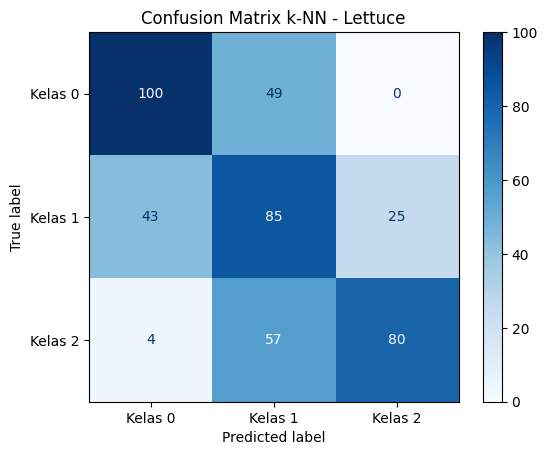

Accuracy : 0.5982
Precision: 0.6291
Recall   : 0.598
F1-Score : 0.6068

              precision    recall  f1-score   support

     Kelas 0       0.68      0.67      0.68       149
     Kelas 1       0.45      0.56      0.49       153
     Kelas 2       0.76      0.57      0.65       141

    accuracy                           0.60       443
   macro avg       0.63      0.60      0.61       443
weighted avg       0.63      0.60      0.60       443



In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_knn)
print("Confusion Matrix:")
print(cm)
ConfusionMatrixDisplay(cm, display_labels=nama_kelas).plot(cmap='Blues')
plt.title("Confusion Matrix k-NN - Lettuce")
plt.show()

# Metrik evaluasi (rata-rata macro untuk multi-kelas)
print("Accuracy :", round(accuracy_score(y_test, y_pred_knn), 4))
print("Precision:", round(precision_score(y_test, y_pred_knn, average='macro', zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_knn, average='macro', zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred_knn, average='macro', zero_division=0), 4))
print()
print(classification_report(y_test, y_pred_knn, target_names=nama_kelas, zero_division=0))

In [8]:
# Hitung manual dari confusion matrix (sesuai rumus pada jobsheet)
# Accuracy = jumlah diagonal / total
acc_manual = np.trace(cm) / np.sum(cm)
print("Accuracy manual:", round(acc_manual, 4))

# Precision & Recall per kelas
for i, k in enumerate(nama_kelas):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    prec = TP / (TP + FP) if (TP + FP) else 0
    rec  = TP / (TP + FN) if (TP + FN) else 0
    print(f"{k}: TP={TP}, FP={FP}, FN={FN} | Precision={prec:.4f}, Recall={rec:.4f}")

Accuracy manual: 0.5982
Kelas 0: TP=100, FP=47, FN=49 | Precision=0.6803, Recall=0.6711
Kelas 1: TP=85, FP=106, FN=68 | Precision=0.4450, Recall=0.5556
Kelas 2: TP=80, FP=25, FN=61 | Precision=0.7619, Recall=0.5674


### 1.2 Kurva ROC dan AUC

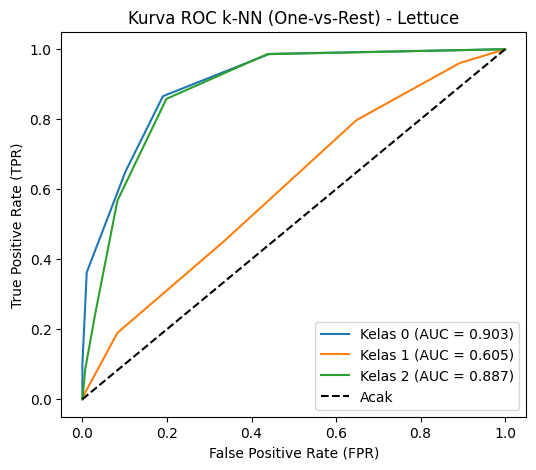

In [9]:
from sklearn.metrics import roc_curve, auc

proba_knn = knn.predict_proba(X_test)
Y_onehot = np.eye(n_kelas)[y_test]

plt.figure(figsize=(6,5))
for i, k in enumerate(nama_kelas):
    fpr, tpr, _ = roc_curve(Y_onehot[:, i], proba_knn[:, i])
    plt.plot(fpr, tpr, label=f"{k} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0,1], [0,1], 'k--', label="Acak")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Kurva ROC k-NN (One-vs-Rest) - Lettuce")
plt.legend()
plt.show()

---
## 2. JST / ANN
### 2.1 Perceptron Sederhana (Gerbang AND)


In [10]:
# Data input (X) dan target (y) -> AND gate
X_and = np.array([[0,0],[0,1],[1,0],[1,1]])
y_and = np.array([0,0,0,1])

w = np.random.rand(2)
b = np.random.rand(1)
lr = 0.1

def activation_step(x):
    return 1 if x >= 0 else 0

for epoch in range(10):
    for i in range(len(X_and)):
        z = np.dot(X_and[i], w) + b
        y_pred = activation_step(z)
        error = y_and[i] - y_pred
        w += lr * error * X_and[i]
        b += lr * error
    print(f"Epoch {epoch+1}, bobot: {w}, bias: {b}")

print("\nPrediksi AND:")
for i in range(len(X_and)):
    print(X_and[i], "->", activation_step(np.dot(X_and[i], w) + b))

Epoch 1, bobot: [0.56359557 0.04439954], bias: [0.67470489]
Epoch 2, bobot: [ 0.46359557 -0.05560046], bias: [0.37470489]
Epoch 3, bobot: [ 0.36359557 -0.15560046], bias: [0.07470489]
Epoch 4, bobot: [ 0.36359557 -0.05560046], bias: [-0.02529511]
Epoch 5, bobot: [ 0.26359557 -0.05560046], bias: [-0.12529511]
Epoch 6, bobot: [0.26359557 0.04439954], bias: [-0.12529511]
Epoch 7, bobot: [0.26359557 0.14439954], bias: [-0.12529511]
Epoch 8, bobot: [0.26359557 0.14439954], bias: [-0.22529511]
Epoch 9, bobot: [0.26359557 0.24439954], bias: [-0.22529511]
Epoch 10, bobot: [0.26359557 0.14439954], bias: [-0.32529511]

Prediksi AND:
[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1


---
## Praktikum 1 - JST 2 Layer dengan Forward Pass & Backpropagation Manual (XOR)


In [11]:
# Dataset XOR
X_xor = np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor = np.array([[0],[1],[1],[0]])

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):      # x sudah berupa output sigmoid
    return x * (1 - x)

# --- Konfigurasi awal (sesuai jobsheet): hidden = 2, aktivasi sigmoid ---
np.random.seed(42)
input_size, hidden_size, output_size = 2, 2, 1
lr = 0.1

W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X_xor, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y_xor - a2

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X_xor.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        loss = np.mean(np.square(error))
        print(f"Epoch {epoch}, Loss: {loss}")

print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2558299419444368
Epoch 1000, Loss: 0.24940565956551236
Epoch 2000, Loss: 0.24544465159719808
Epoch 3000, Loss: 0.2047073304071442
Epoch 4000, Loss: 0.15320405369970766
Epoch 5000, Loss: 0.13869146014771938
Epoch 6000, Loss: 0.13359363321851758
Epoch 7000, Loss: 0.13115112181268004
Epoch 8000, Loss: 0.12974916048385188
Epoch 9000, Loss: 0.12884908965171127
Prediksi:
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]


### Tugas 1


In [12]:
def relu(x):
    return np.maximum(0, x)

def train_xor(hidden_size=2, activation='sigmoid', epochs=10000, lr=0.1, seed=42):
    np.random.seed(seed)
    W1 = np.random.randn(2, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, 1)
    b2 = np.zeros((1, 1))

    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X_xor, W1) + b1
        a1 = sigmoid(z1) if activation == 'sigmoid' else relu(z1)
        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)                       # output tetap sigmoid

        error = y_xor - a2

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        turunan = sigmoid_derivative(a1) if activation == 'sigmoid' else (z1 > 0).astype(float)
        d_a1 = np.dot(d_a2, W2.T) * turunan
        d_W1 = np.dot(X_xor.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    loss_akhir = np.mean(np.square(y_xor - a2))
    return loss_akhir, a2

hasil_xor = []
for h, act in [(2,'sigmoid'), (3,'sigmoid'), (2,'relu'), (3,'relu')]:
    loss_akhir, pred = train_xor(hidden_size=h, activation=act)
    hasil_xor.append({"Hidden neuron": h, "Aktivasi hidden": act,
                      "Loss akhir": loss_akhir,
                      "Prediksi": np.round(pred.ravel(), 3)})

pd.DataFrame(hasil_xor)

,Hidden neuron,Aktivasi hidden,Loss akhir,Prediksi
0,2,sigmoid,0.128227,"[0.053, 0.496, 0.951, 0.503]"
1,3,sigmoid,0.002297,"[0.025, 0.953, 0.951, 0.063]"
2,2,relu,0.125047,"[0.5, 0.989, 0.5, 0.009]"
3,3,relu,0.000352,"[0.03, 0.986, 0.986, 0.012]"


---
## Praktikum 2 - Klasifikasi dengan Keras (Dataset Lettuce)


In [13]:
# Bangun model (sama seperti jobsheet: 10 -> 8 -> softmax)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_fitur,)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(n_kelas, activation='softmax')
])
model.summary()

# Kompilasi
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
history = model.fit(X_train, y_train_oh, epochs=50, batch_size=8, verbose=0)

# Evaluasi
loss, acc = model.evaluate(X_test, y_test_oh, verbose=0)
print(f"Loss  : {loss:.4f}")
print(f"Akurasi: {acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675 (2.64 KB)

 Trainable params: 675 (2.64 KB)

 Non-trainable params: 0 (0.00 B)

Loss  : 0.0862
Akurasi: 0.9661


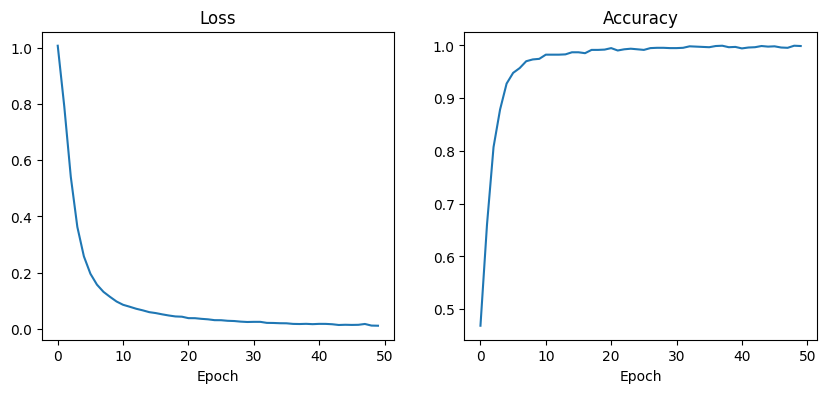

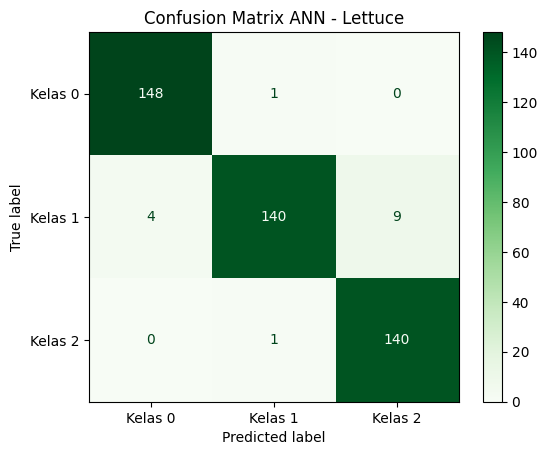

              precision    recall  f1-score   support

     Kelas 0       0.97      0.99      0.98       149
     Kelas 1       0.99      0.92      0.95       153
     Kelas 2       0.94      0.99      0.97       141

    accuracy                           0.97       443
   macro avg       0.97      0.97      0.97       443
weighted avg       0.97      0.97      0.97       443



In [14]:
# Kurva pelatihan
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history.history['loss']); plt.title('Loss'); plt.xlabel('Epoch')
plt.subplot(1,2,2); plt.plot(history.history['accuracy']); plt.title('Accuracy'); plt.xlabel('Epoch')
plt.show()

# Confusion matrix hasil ANN
y_pred_ann = np.argmax(model.predict(X_test, verbose=0), axis=1)
cm_ann = confusion_matrix(y_test, y_pred_ann)
ConfusionMatrixDisplay(cm_ann, display_labels=nama_kelas).plot(cmap='Greens')
plt.title("Confusion Matrix ANN - Lettuce")
plt.show()
print(classification_report(y_test, y_pred_ann, target_names=nama_kelas, zero_division=0))

### Tugas 2


In [15]:
def build_model(hidden=(10, 8), activation='relu'):
    layers = [tf.keras.layers.Input(shape=(n_fitur,))]
    for n in hidden:
        layers.append(tf.keras.layers.Dense(n, activation=activation))
    layers.append(tf.keras.layers.Dense(n_kelas, activation='softmax'))
    m = tf.keras.Sequential(layers)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def jalankan(hidden, activation='relu', epochs=50, batch_size=8):
    tf.keras.utils.set_random_seed(42)
    m = build_model(hidden, activation)
    t0 = time.time()
    m.fit(X_train, y_train_oh, epochs=epochs, batch_size=batch_size, verbose=0)
    waktu = time.time() - t0
    loss, acc = m.evaluate(X_test, y_test_oh, verbose=0)
    return loss, acc, waktu

hasil_t2 = []
for hidden in [(10, 8), (5, 4), (20, 10), (64, 32)]:
    loss, acc, waktu = jalankan(hidden)
    hasil_t2.append({"Hidden layer": str(hidden), "Loss": round(loss,4),
                     "Akurasi": round(acc,4), "Waktu (detik)": round(waktu,2)})
pd.DataFrame(hasil_t2)

,Hidden layer,Loss,Akurasi,Waktu (detik)
0,"(10, 8)",0.0960,0.9616,23.84
1,"(5, 4)",0.1128,0.9526,23.84
2,"(20, 10)",0.1369,0.9616,24.03
3,"(64, 32)",0.1929,0.9436,23.57


### Tugas 3


In [16]:
hasil_t3 = []
for act in ['sigmoid', 'relu']:
    loss, acc, waktu = jalankan((10, 8), activation=act)
    hasil_t3.append({"Aktivasi": act, "Loss": round(loss,4),
                     "Akurasi": round(acc,4), "Waktu (detik)": round(waktu,2)})
pd.DataFrame(hasil_t3)

,Aktivasi,Loss,Akurasi,Waktu (detik)
0,sigmoid,0.082,0.9639,23.81
1,relu,0.096,0.9616,24.04


---
## Praktikum 3 - Keras untuk Regresi (Dataset Lettuce)


In [17]:
if not target_kontinu:
    print("Target dataset berupa kelas/kategori, bukan angka kontinu -> Praktikum 3 (regresi) dilewati.")
    print("Jika ada kolom numerik lain yang ingin diprediksi, ubah TARGET di bagian persiapan lalu jalankan ulang dari atas.")
else:
    # Split data regresi
    Xr_train, Xr_test, yr_train, yr_test = train_test_split(
        X.values, y_reg.reshape(-1,1), test_size=0.2, random_state=42)

    # Normalisasi (X dan y masing-masing punya scaler sendiri)
    sc_X = StandardScaler()
    sc_y = StandardScaler()
    Xr_train_s = sc_X.fit_transform(Xr_train)
    Xr_test_s  = sc_X.transform(Xr_test)
    yr_train_s = sc_y.fit_transform(yr_train)
    yr_test_s  = sc_y.transform(yr_test)

    # Model (sama seperti jobsheet: Dense 10 relu -> Dense 1)
    model_reg = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_fitur,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    model_reg.compile(optimizer='adam', loss='mse')
    model_reg.fit(Xr_train_s, yr_train_s, epochs=100, verbose=0)

    # Evaluasi
    loss_reg = model_reg.evaluate(Xr_test_s, yr_test_s, verbose=0)
    print("Loss (MSE, data ternormalisasi):", round(loss_reg, 4))
    pred = sc_y.inverse_transform(model_reg.predict(Xr_test_s, verbose=0))
    print("Contoh prediksi vs aktual:")
    print(pd.DataFrame({"Aktual": yr_test.ravel()[:10], "Prediksi": pred.ravel()[:10].round(2)}))

Loss (MSE, data ternormalisasi): 0.014
Contoh prediksi vs aktual:
   Aktual  Prediksi
0    0.64      0.64
1    0.67      0.67
2    0.57      0.57
3    0.72      0.72
4    0.75      0.76
5    0.67      0.67
6    0.51      0.51
7    0.65      0.65
8    0.58      0.58
9    0.51      0.51


### Tugas 4


In [18]:
if target_kontinu:
    hasil_t4 = []
    for lr_ in [0.1, 0.01, 0.001, 0.0001]:
        tf.keras.utils.set_random_seed(42)
        m = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(n_fitur,)),
            tf.keras.layers.Dense(10, activation='relu'),
            tf.keras.layers.Dense(1)
        ])
        m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_), loss='mse')
        h_ = m.fit(Xr_train_s, yr_train_s, epochs=100, verbose=0)
        hasil_t4.append({"Learning rate": lr_,
                         "Loss latih akhir": round(h_.history['loss'][-1], 4),
                         "Loss uji": round(m.evaluate(Xr_test_s, yr_test_s, verbose=0), 4)})
    display(pd.DataFrame(hasil_t4))
else:
    print("Dilewati (target bukan kontinu).")

,Learning rate,Loss latih akhir,Loss uji
0,0.1000,0.0106,0.0037
1,0.0100,0.0018,0.0018
2,0.0010,0.0016,0.0021
3,0.0001,0.0432,0.0534


### MLP Regresi dengan Grafik Loss/MAE dan RMSE


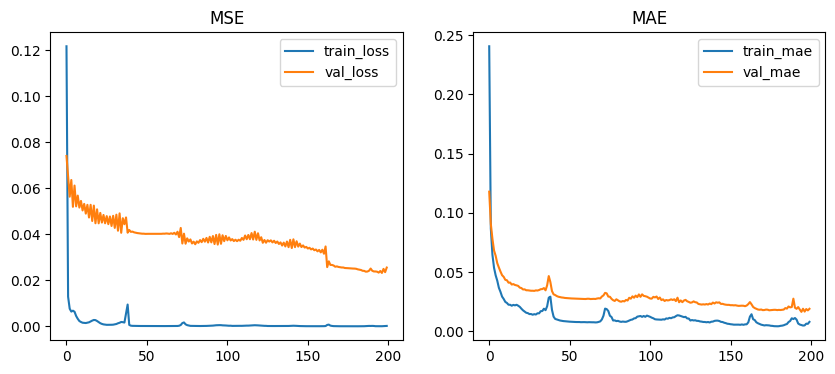

RMSE: 0.1598979259197017


In [19]:
from sklearn.metrics import mean_squared_error
from tensorflow.keras.optimizers import Adam

if target_kontinu:
    Xs = StandardScaler().fit_transform(X.values)
    Xm_train, Xm_val, ym_train, ym_val = train_test_split(Xs, y_reg, test_size=0.2, random_state=42)

    model_mlp = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(Xm_train.shape[1],)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    model_mlp.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

    h = model_mlp.fit(Xm_train, ym_train, validation_data=(Xm_val, ym_val),
                      epochs=200, batch_size=32, verbose=0)

    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
    plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
    plt.show()

    pred = model_mlp.predict(Xm_val, verbose=0)
    print('RMSE:', np.sqrt(mean_squared_error(ym_val, pred)))
else:
    print("Dilewati (target bukan kontinu).")

---
## Tugas Praktikum - Klasifikasi dengan JST (pengganti MNIST → Lettuce)


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# 2. Bangun model JST (2 hidden layer)
model_tp = Sequential([
    Input(shape=(n_fitur,)),                  # pengganti Flatten
    Dense(128, activation='relu'),            # Hidden layer 1
    Dense(64, activation='relu'),             # Hidden layer 2
    Dense(n_kelas, activation='softmax')      # Output layer
])

# 3. Kompilasi model
model_tp.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model
model_tp.fit(X_train, y_train_oh, epochs=50, batch_size=16, verbose=0)

# 5. Evaluasi model
loss, acc = model_tp.evaluate(X_test, y_test_oh, verbose=0)
print(f"Akurasi pada data uji: {acc:.4f}")

Akurasi pada data uji: 0.9503


### Eksperimen parameter lain
- Ubah neuron hidden layer (256 dan 128)
- Tambah satu hidden layer lagi
- Bandingkan akurasi dan waktu pelatihan
- Sigmoid vs ReLU

In [21]:
konfigurasi = [
    ("Awal: 128-64 (ReLU)",            (128, 64),      'relu'),
    ("256-128 (ReLU)",                 (256, 128),     'relu'),
    ("Tambah layer: 256-128-64 (ReLU)",(256, 128, 64), 'relu'),
    ("128-64 (Sigmoid)",               (128, 64),      'sigmoid'),
    ("256-128 (Sigmoid)",              (256, 128),     'sigmoid'),
]

hasil_tp = []
for nama, hidden, act in konfigurasi:
    loss, acc, waktu = jalankan(hidden, activation=act, epochs=50, batch_size=16)
    hasil_tp.append({"Konfigurasi": nama, "Loss": round(loss,4),
                     "Akurasi": round(acc,4), "Waktu latih (detik)": round(waktu,2)})

tabel_tp = pd.DataFrame(hasil_tp)
tabel_tp

,Konfigurasi,Loss,Akurasi,Waktu latih (detik)
0,Awal: 128-64 (ReLU),0.1674,0.9549,14.21
1,256-128 (ReLU),0.1973,0.9436,14.37
2,Tambah layer: 256-128-64 (ReLU),0.2123,0.9458,15.14
3,128-64 (Sigmoid),0.0642,0.9752,13.95
4,256-128 (Sigmoid),0.1096,0.9639,14.37


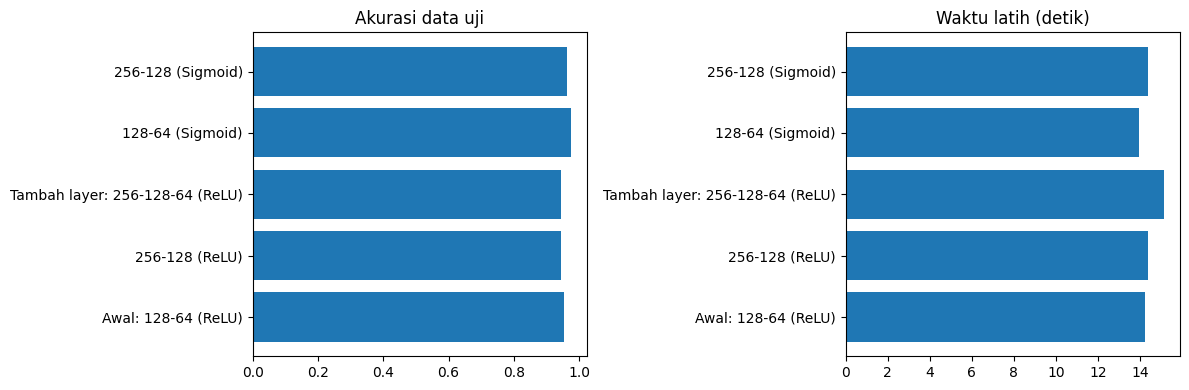

In [22]:
# Grafik perbandingan
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].barh(tabel_tp["Konfigurasi"], tabel_tp["Akurasi"]); ax[0].set_title("Akurasi data uji")
ax[1].barh(tabel_tp["Konfigurasi"], tabel_tp["Waktu latih (detik)"]); ax[1].set_title("Waktu latih (detik)")
plt.tight_layout()
plt.show()